# Coupon Acceptance Analysis
 
## Business Problem
 
The objective of this analysis is to determine the characteristics of customers who accept coupons and those who reject them.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [ ]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [6]:
# Check the dataset structure, duplicate rows, and missing values.
print(f"Dataset shape: {data.shape[0]:,} rows x {data.shape[1]} columns")
print(f"Duplicate rows: {data.duplicated().sum():,}")

missing = data.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(data) * 100).round(2)
})

print("\nColumns with missing values:")
print(missing_summary if not missing_summary.empty else "None")

Dataset shape: 12,684 rows x 26 columns
Duplicate rows: 74

Columns with missing values:
                      missing_count  missing_percent
car                           12576            99.15
CoffeeHouse                     217             1.71
Restaurant20To50                189             1.49
CarryAway                       151             1.19
RestaurantLessThan20            130             1.02
Bar                             107             0.84


3. Decide what to do about your missing data -- drop, replace, other...

In [9]:
# Keep all observations, drop the nearly empty car column, and label
# remaining categorical missing values explicitly as "Unknown".
data = data.drop(columns=["car"], errors="ignore").copy()
categorical_columns = data.select_dtypes(include=["object", "str"]).columns
data[categorical_columns] = data[categorical_columns].fillna("Unknown")

print(f"Dropped column: car")
print(f"Remaining missing values: {data.isna().sum().sum()}")
print(f"Cleaned dataset shape: {data.shape[0]:,} rows x {data.shape[1]} columns")

Dropped column: car
Remaining missing values: 0
Cleaned dataset shape: 12,684 rows x 25 columns


4. What proportion of the total observations chose to accept the coupon?



In [11]:
acceptance_rate = data["Y"].mean()
print(f"Overall coupon acceptance rate: {acceptance_rate:.2%}")

Overall coupon acceptance rate: 56.84%


5. Use a bar plot to visualize the `coupon` column.

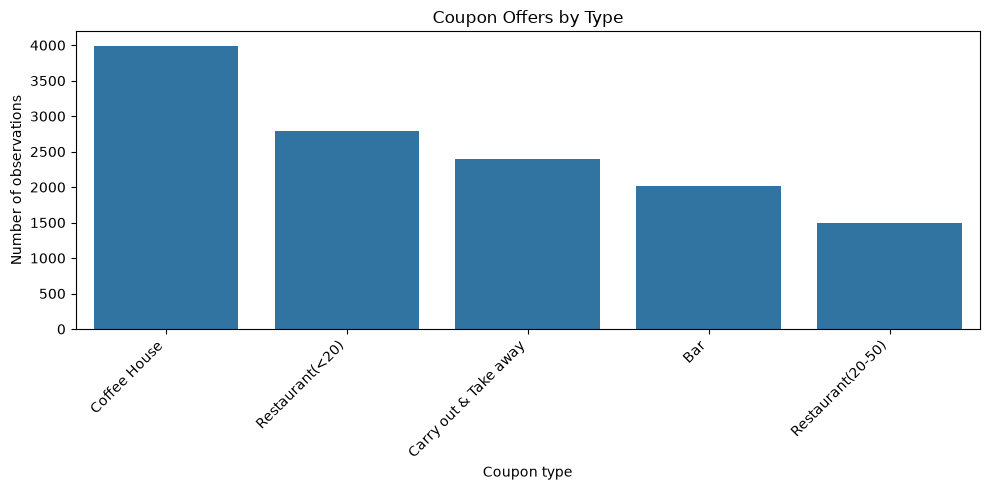

In [12]:
coupon_order = data["coupon"].value_counts().index

plt.figure(figsize=(10, 5))
sns.countplot(data=data, x="coupon", order=coupon_order)
plt.title("Coupon Offers by Type")
plt.xlabel("Coupon type")
plt.ylabel("Number of observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

6. Use a histogram to visualize the temperature column.

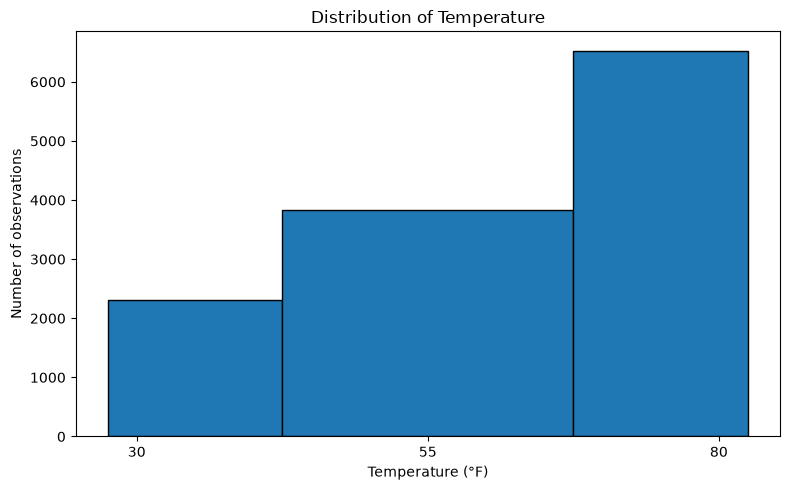

In [13]:
plt.figure(figsize=(8, 5))
plt.hist(data["temperature"], bins=[27.5, 42.5, 67.5, 82.5], edgecolor="black")
plt.title("Distribution of Temperature")
plt.xlabel("Temperature (°F)")
plt.ylabel("Number of observations")
plt.xticks([30, 55, 80])
plt.tight_layout()
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [14]:
bar_coupons = data.loc[data["coupon"].eq("Bar")].copy()
print(f"Bar coupon observations: {len(bar_coupons):,}")
bar_coupons.head()

Bar coupon observations: 2,017


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,Unknown,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,Unknown,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,Unknown,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


In [16]:
bar_coupons = data[data["coupon"] == "Bar"]
bar_acceptance_rate = bar_coupons["Y"].mean()

print(f"Proportion of bar coupons accepted: {bar_acceptance_rate:.2%}")

Proportion of bar coupons accepted: 41.00%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [17]:
bar_3_or_fewer = bar_coupons[bar_coupons["Bar"].isin(["never", "less1", "1~3"])]
bar_more_than_3 = bar_coupons[bar_coupons["Bar"].isin(["4~8", "gt8"])]

rate_3_or_fewer = bar_3_or_fewer["Y"].mean()
rate_more_than_3 = bar_more_than_3["Y"].mean()

print(f"3 or fewer bar visits: {len(bar_3_or_fewer):,} observations, {rate_3_or_fewer:.2%} accepted")
print(f"More than 3 bar visits: {len(bar_more_than_3):,} observations, {rate_more_than_3:.2%} accepted")
print(f"Difference: {(rate_more_than_3 - rate_3_or_fewer):.2%}")

3 or fewer bar visits: 1,797 observations, 37.06% accepted
More than 3 bar visits: 199 observations, 76.88% accepted
Difference: 39.82%


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [18]:
more_than_once = bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])
over_25 = bar_coupons["age"].isin(["26", "31", "36", "41", "46", "50plus"])

bar_over_25_group = bar_coupons[more_than_once & over_25]
bar_all_others = bar_coupons[~(more_than_once & over_25)]

rate_over_25_group = bar_over_25_group["Y"].mean()
rate_all_others = bar_all_others["Y"].mean()

print(f"More than once/month and over 25: {len(bar_over_25_group):,} observations, {rate_over_25_group:.2%} accepted")
print(f"All others: {len(bar_all_others):,} observations, {rate_all_others:.2%} accepted")
print(f"Difference: {(rate_over_25_group - rate_all_others):.2%}")

More than once/month and over 25: 420 observations, 69.52% accepted
All others: 1,597 observations, 33.50% accepted
Difference: 36.02%


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [19]:
more_than_once = bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])
not_a_kid = bar_coupons["passanger"].ne("Kid(s)")
not_farming_fishing_forestry = ~bar_coupons["occupation"].str.contains(
    "Farming|Fishing|Forestry", case=False, na=False
)

bar_target_group = bar_coupons[
    more_than_once & not_a_kid & not_farming_fishing_forestry
]
bar_other_group = bar_coupons[
    ~(more_than_once & not_a_kid & not_farming_fishing_forestry)
]

rate_target_group = bar_target_group["Y"].mean()
rate_other_group = bar_other_group["Y"].mean()

print(f"Target group: {len(bar_target_group):,} observations, {rate_target_group:.2%} accepted")
print(f"All others: {len(bar_other_group):,} observations, {rate_other_group:.2%} accepted")
print(f"Difference: {(rate_target_group - rate_other_group):.2%}")

Target group: 551 observations, 71.32% accepted
All others: 1,466 observations, 29.60% accepted
Difference: 41.72%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [20]:
more_than_once = bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])
not_a_kid = bar_coupons["passanger"].ne("Kid(s)")
not_widowed = bar_coupons["maritalStatus"].ne("Widowed")
under_30 = bar_coupons["age"].isin(["below21", "21", "26"])
cheap_restaurant_more_than_4 = bar_coupons["RestaurantLessThan20"].isin(["4~8", "gt8"])
income_less_than_50k = bar_coupons["income"].isin([
    "Less than $12500",
    "$12500 - $24999",
    "$25000 - $37499",
    "$37500 - $49999",
])

condition_1 = more_than_once & not_a_kid & not_widowed
condition_2 = more_than_once & under_30
condition_3 = cheap_restaurant_more_than_4 & income_less_than_50k

bar_combined_group = bar_coupons[condition_1 | condition_2 | condition_3]
bar_remaining_group = bar_coupons[~(condition_1 | condition_2 | condition_3)]

rate_combined_group = bar_combined_group["Y"].mean()
rate_remaining_group = bar_remaining_group["Y"].mean()

print(f"Combined group: {len(bar_combined_group):,} observations, {rate_combined_group:.2%} accepted")
print(f"All others: {len(bar_remaining_group):,} observations, {rate_remaining_group:.2%} accepted")
print(f"Difference: {(rate_combined_group - rate_remaining_group):.2%}")

Combined group: 776 observations, 58.89% accepted
All others: 1,241 observations, 29.81% accepted
Difference: 29.08%


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [21]:
print(
    "Hypothesis: Drivers who already visit bars regularly are much more likely to "
    "accept bar coupons, especially when they are over 25 and do not have a kid "
    "as a passenger. The strongest observed group, drivers who visit bars more "
    "than once a month, have no kid passenger, and work outside farming, fishing, "
    "or forestry, accepted at a higher rate than the comparison group. These "
    "results show association, not causation."
)
print(f"\nSupporting rates:")
print(f"- More than 3 bar visits: {rate_more_than_3:.2%}")
print(f"- More than once/month and over 25: {rate_over_25_group:.2%}")
print(f"- Target group from question 5: {rate_target_group:.2%}")
print(f"- Combined group from question 6: {rate_combined_group:.2%}")

Hypothesis: Drivers who already visit bars regularly are much more likely to accept bar coupons, especially when they are over 25 and do not have a kid as a passenger. The strongest observed group, drivers who visit bars more than once a month, have no kid passenger, and work outside farming, fishing, or forestry, accepted at a higher rate than the comparison group. These results show association, not causation.

Supporting rates:
- More than 3 bar visits: 76.88%
- More than once/month and over 25: 69.52%
- Target group from question 5: 71.32%
- Combined group from question 6: 58.89%


### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [22]:
coffee_house_coupons = data.loc[data["coupon"].eq("Coffee House")].copy()
coffeehouse_acceptance = (
    coffee_house_coupons.groupby("CoffeeHouse", sort=False)["Y"]
    .agg(observations="size", acceptance_rate="mean")
)
coffeehouse_acceptance["acceptance_rate"] = (
    coffeehouse_acceptance["acceptance_rate"] * 100
).round(2)

print(f"Coffee House coupon observations: {len(coffee_house_coupons):,}")
print("Acceptance by coffee-house visit frequency:")
coffeehouse_acceptance

Coffee House coupon observations: 3,996
Acceptance by coffee-house visit frequency:


,observations,acceptance_rate
CoffeeHouse,,
never,927,18.88
less1,1075,48.19
4~8,538,68.59
1~3,1042,64.78
gt8,342,65.79
Unknown,72,45.83
